<!-- colab-badge -->
[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/RemusTeodorescu/DL-for-Engineers-Public-Course/blob/main/miniprojects/MP8.2A/MP8.2A_00_problem.ipynb)

*Open this notebook in Google Colab with a GPU runtime (Runtime → Change runtime type → T4 GPU). Its first code cell fetches the library files from the public course repository.*

<!-- course-header v3 -->

**Deep Learning for Engineering** · MSc, Aalborg University · 2026

Developed by **Remus Teodorescu** (ret@et.aau.dk), with support from Research Assistant **Noman Khan** (nomank@energy.aau.dk).

*Reference texts — read for the theory. Used as an **inspirational source** for this course, not as a source of its code:*

- Liu, *PINN with Python*, 2025.
- Raissi, Perdikaris & Karniadakis, *Physics-informed neural networks*, J. Comput. Phys. 378 (2019) 686–707.
- Prince, *Understanding Deep Learning*, MIT Press 2023.

Every notebook in this course has been **written and rewritten by the authors named above**. The code, the problems, the data and the exposition are **original to this course** and are not derived from any publisher's code listings or companion notebooks. Where notation matches a textbook's it is the standard notation of the field, and where an idea is a named author's it is cited as theirs in the text.

See `docs/PROVENANCE.md` for what each reference is cited for, set by set.

---

# MP8.2A · Thermal Cycling with Natural Convection
## 00 · The Problem

*Mini project of the course **Deep Learning for Engineering**, Part 2. Five notebooks, run in order:*

**00 The Problem** → 01 The Data and the Physics → 02 The Reference Model and the Ground Truth → 03 The Physics-Informed Network → 04 The Report

*Notebooks 00 to 02 are given and solved: read them, run them, and use what they build. Notebooks 03 and 04 are yours.*

In [1]:
# files-cell (mini project) ----------------------------------------------------
# The library files must sit beside the notebook. Locally they already do. On
# Google Colab they are fetched from the public course repository on every
# run, so a file left over from an earlier session cannot shadow it.
import os, sys, urllib.request
EXERCISE = (['course_core.py', 'pinn_core.py', 'heatsink.py'], "https://raw.githubusercontent.com/RemusTeodorescu/DL-for-Engineers-Public-Course/main/exercises/Ex08-heatsink-cooling/")
PROJECT = (['mp82a.py', 'MP8.2A_truth.npz'], "https://raw.githubusercontent.com/RemusTeodorescu/DL-for-Engineers-Public-Course/main/miniprojects/MP8.2A/")
ON_COLAB = "google.colab" in sys.modules
for files, url in (EXERCISE, PROJECT):
    for f in files:
        if ON_COLAB or not os.path.exists(f):
            if not ON_COLAB and os.path.exists(os.path.join("..", "..", "exercises", "Ex08-heatsink-cooling", f)):
                import shutil; shutil.copy(os.path.join("..", "..", "exercises", "Ex08-heatsink-cooling", f), f)
            else:
                urllib.request.urlretrieve(url + f, f)
            print("fetched", f)
for _m in ['course_core', 'pinn_core', 'heatsink', 'mp82a']:
    sys.modules.pop(_m, None)
print("files ready")

files ready


In [2]:
# --- setup ---------------------------------------------------------------
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
import course_core as cc
import heatsink as hs
import mp82a as mp
torch.set_default_dtype(torch.float64)                   # a second derivative of a network needs double precision
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"  # the GPU, when the runtime has one
cc.keep_outputs("MP8.2A_outputs")                            # results kept between the notebooks (Google Drive on Colab)
print("device:", DEVICE, "| torch", torch.__version__)

device: cpu | torch 2.14.1+cu130


## 1 · What is computed, and why an engineer wants it

A power module - the IGBTs or MOSFETs of a motor drive, an inverter or a charger - is rarely loaded steadily. A lift, a crane or a test bench runs it in **duty cycles**: on for a while, off for a while, over and over. Every cycle heats the module and lets it cool again, and every swing of temperature strains the solder layers and the bond wires, because silicon, copper and aluminium expand by different amounts. Fatigue from these swings is the most common way a power module wears out, and the number of cycles a module survives falls steeply with the **size of the swing** and with the **peak temperature** reached.

So the quantity an engineer wants is not one temperature but a history: **the temperature of the module, cycle by cycle**, its peak and its trough, and how both change with the module's power. A lifetime study repeats this for many mission profiles and many powers, so the model is run many times. That is where a fast model pays.

This mini project computes that history for the heat sink of Ex08, under a train of ten pulses, **for any module power between 100 and 200 W**, with one network.

## 2 · The heat sink, and what is new against Ex08

The heat sink is Ex08's: an extruded aluminium sink with a 100 mm wide, 10 mm thick base plate and ten straight fins, cooled by a fan in an enclosure at 40 °C. The module sits on the middle 30 mm of the base. The cell below draws it and prints its data.

**What is new.** Ex08 cools the fins with one constant coefficient, $h = 40$ W/(m²K), the fan's forced air. In a real enclosure the air the fins warm also rises by its own buoyancy - **natural convection** - and the hotter the fins, the stronger it is. The coefficient on the fins becomes

$$h(\Delta T) = h_\mathrm{fan} + S \cdot C_\mathrm{nat}\left(\frac{\Delta T}{L_\mathrm{fin}}\right)^{1/4}$$

where $\Delta T$ is the rise of the fin root above the air, $L_\mathrm{fin} = 40$ mm the fin length, and $C_\mathrm{nat} = 1.42$ W/(m$^{7/4}$K$^{5/4}$) the laminar natural-convection coefficient of a vertical plate in air (Incropera & DeWitt, ch. 9; **assumed** here, from memory). $S = 1$ is the strength of the change; at $S = 0$ the problem is exactly Ex08's.

The fins' efficiency depends on $h$, so the **effective coefficient** the finned face puts on the base plate, $h_\mathrm{eff}$, is Ex08's fin calculation evaluated with $h(\Delta T)$. It rises from 322 W/(m²K) with the sink at the air's temperature to about 370 W/(m²K) at a 20 K rise.

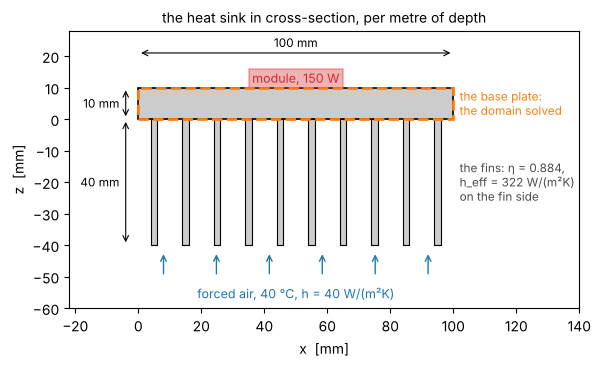

     base plate  100 mm wide, 10 mm thick, 100 mm deep
 aluminium 6061  k = 167 W/(m·K), ρc_p = 2.43 MJ/(m³K)
           fins  10 fins, 2 × 40 mm, pitch 10 mm
            air  40 °C, fan h = 40 W/(m²K)
         module  footprint 35–65 mm, power P = 100–200 W
     duty cycle  on 20 s every 60 s, 10 cycles, 600 s in all


In [3]:
# The heat sink of Ex08, and its data
fig, ax = plt.subplots(figsize=(8, 3.6))
hs.draw_heatsink(ax)                                     # Ex08's drawing of the sink, the module and the domain
plt.show()

rows = [("base plate", f"{hs.W_BASE*1e3:.0f} mm wide, {hs.T_BASE*1e3:.0f} mm thick, {hs.DEPTH*1e3:.0f} mm deep"),
        ("aluminium 6061", f"k = {hs.K_AL:.0f} W/(m·K), ρc_p = {hs.RHO_CP/1e6:.2f} MJ/(m³K)"),
        ("fins", f"{hs.N_FINS} fins, {hs.T_FIN*1e3:.0f} × {hs.L_FIN*1e3:.0f} mm, pitch {hs.PITCH*1e3:.0f} mm"),
        ("air", f"{hs.T_AIR:.0f} °C, fan h = {hs.H_AIR:.0f} W/(m²K)"),
        ("module", f"footprint {hs.MODULE[0]*1e3:.0f}–{hs.MODULE[1]*1e3:.0f} mm, power P = {mp.P_MIN:.0f}–{mp.P_MAX:.0f} W"),
        ("duty cycle", f"on {mp.T_ON:.0f} s every {mp.PERIOD:.0f} s, {mp.CYCLES} cycles, {mp.T_END:.0f} s in all")]
for k, v in rows:
    print(f"{k:>15}  {v}")

**What you should see.** The sink in cross-section, the module on top, the domain - the base plate - outlined; and the table of its data. Every value is Ex08's except the power range and the duty cycle.

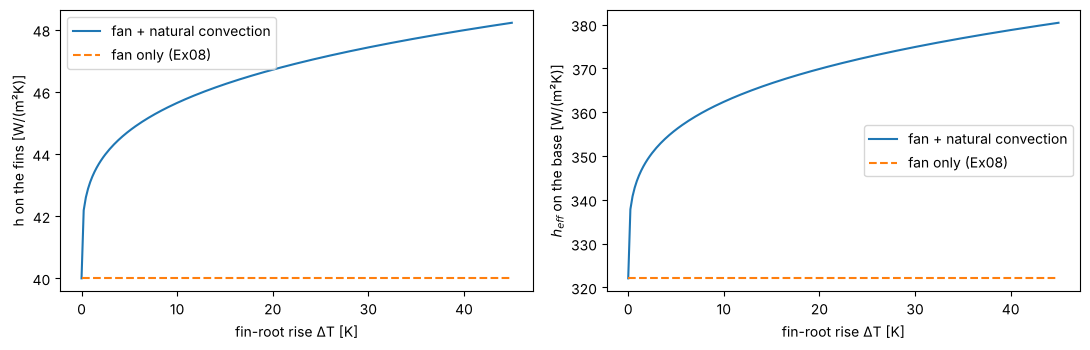

ΔT =  0 K:  h =  40.0 W/(m²K),  h_eff = 322.1 W/(m²K)
ΔT = 10 K:  h =  45.6 W/(m²K),  h_eff = 362.4 W/(m²K)
ΔT = 20 K:  h =  46.7 W/(m²K),  h_eff = 369.9 W/(m²K)
ΔT = 40 K:  h =  48.0 W/(m²K),  h_eff = 378.8 W/(m²K)


In [4]:
# The coefficient on the fins, with and without natural convection
dT = np.linspace(0, 45, 200)                             # K, the fin-root rise above the air
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(dT, mp.h_air(dT), label="fan + natural convection")
ax[0].plot(dT, mp.h_air(dT, s_nat=0.0), "--", label="fan only (Ex08)")
ax[0].set_xlabel("fin-root rise ΔT [K]"); ax[0].set_ylabel("h on the fins [W/(m²K)]"); ax[0].legend()
ax[1].plot(dT, mp.h_eff(dT), label="fan + natural convection")
ax[1].plot(dT, mp.h_eff(dT, s_nat=0.0), "--", label="fan only (Ex08)")
ax[1].set_xlabel("fin-root rise ΔT [K]"); ax[1].set_ylabel("$h_{eff}$ on the base [W/(m²K)]"); ax[1].legend()
plt.tight_layout(); plt.show()
for d in (0, 10, 20, 40):
    print(f"ΔT = {d:2d} K:  h = {float(mp.h_air(d)):5.1f} W/(m²K),  h_eff = {float(mp.h_eff(d)):5.1f} W/(m²K)")

**What you should see.** The fan alone gives a flat line; natural convection adds a part that grows with the fourth root of the rise - steeply at first, then slowly. On the base, $h_\mathrm{eff}$ goes from 322 W/(m²K) at no rise to 370 at 20 K and 379 at 40 K: about 15 % more cooling when the sink is hot, which is enough to lower the peak of the tenth cycle by almost 2 K at 150 W.

## 3 · The domain, the equation and its conditions

The fins are collapsed into $h_\mathrm{eff}$, as in Ex08, so the domain is the **base plate in cross-section**: $0 < x < W$ across the base, $0 < z < t_b$ through its thickness ($z = 0$ the fin side, $z = t_b$ the module side), per metre of depth. The unknown is the rise above the air, $\theta(x, z, t) = T - T_\mathrm{air}$, which depends also on the module's power $P$.

$$\rho c_p \frac{\partial \theta}{\partial t} = k\left(\frac{\partial^2 \theta}{\partial x^2} + \frac{\partial^2 \theta}{\partial z^2}\right) \quad \text{in the base plate}$$

| where | condition | why it holds |
|---|---|---|
| module face, on the footprint ($z = t_b$) | $k\,\partial\theta/\partial z = \dfrac{P}{P_0}\,q''\,s(t)$ | the module's losses enter the base through its baseplate; $q'' = 50$ kW/m² at $P_0 = 150$ W, and $s(t)$ is 1 while the module is on |
| module face, off the footprint | $\partial\theta/\partial z = 0$ | still air above the base plate; its heat loss is small against the fins' |
| fin side ($z = 0$) | $k\,\partial\theta/\partial z = h_\mathrm{eff}(\theta)\,\theta$ | the fins, collapsed into one coefficient that now depends on the local rise: **nonlinear** |
| ends ($x = 0$ and $x = W$) | $\partial\theta/\partial x = 0$ | the two 10 mm ends lose little against 0.8 m² of fins |
| start ($t = 0$) | $\theta = 0$ | the sink has stood switched off at the air's temperature |

The equation is **parabolic**: heat diffuses, and the field at any instant depends only on what came before. Two time scales matter. Through the 10 mm thickness heat spreads in $t_b^2/\alpha \approx 1.5$ s, so the fin side follows the module within seconds. Across the 100 mm base it takes $W^2/\alpha \approx 145$ s, longer than one cycle, so the heat spread sideways builds up over several cycles: the history settles into a repeating pattern only after five to eight cycles.

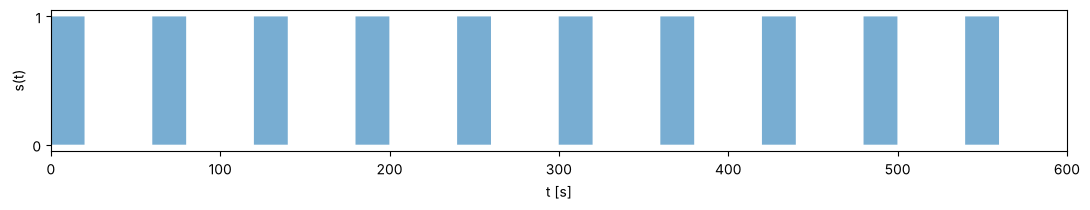

the module switches 20 times: [  0.  20.  60.  80. 120. 140.] ...


In [5]:
# The duty cycle s(t): on for 20 s every 60 s, ten times
t = np.linspace(0, mp.T_END, 6001)
fig, ax = plt.subplots(figsize=(11, 2.2))
ax.fill_between(t, mp.train_on(t).astype(float), step="pre", alpha=0.6)
ax.set_xlabel("t [s]"); ax.set_ylabel("s(t)"); ax.set_yticks([0, 1]); ax.set_xlim(0, mp.T_END)
plt.tight_layout(); plt.show()
print("the module switches", len(mp.SWITCHES), "times:", mp.SWITCHES[:6], "...")

**What you should see.** Ten blocks, 20 s wide, one a minute: 20 switches in all. At every switch the flux jumps, so the temperature's rate of change jumps too: the history the network must represent has **twenty kinks**. Keep that in mind for notebook 03.

## 4 · Why there is no exact solution

Ex08's base plate has an exact solution because every condition is **linear** in $\theta$: the field is a sum of cosines across the base times known functions of $z$ and $t$, and a train of pulses is a sum of steps. With $h_\mathrm{eff}(\theta)$ the fin-side condition multiplies the unknown by a function of itself. A sum of two solutions is then no longer a solution, separation of variables fails, and no series or closed form exists. That is the normal case in engineering: the nonlinearity is mild, but it is enough.

The reference and the ground truth are therefore **numerical**: finite differences in space and Crank-Nicolson in time (notebook 02). They are checked in three ways: on grids each twice as fine, by the energy balance, and at $S = 0$, where they must reproduce Ex08's exact series.

## 5 · What is asked

| quantity | at | required |
|---|---|---|
| the rise of the module's centre, $\theta(W/2, t_b, t)$, over the 600 s | the test powers 115, 165 and 195 W, which you do not train on | every cycle's **peak and trough within 0.3 K** of the ground truth |
| the field across the base plate at 600 s | the same powers | within **0.5 K** everywhere |
| the time to answer a new power online | one Colab T4 runtime | at least **10 times shorter** than the reference model's (notebook 02 measures it) |

One network, trained once, offline, over the whole range of powers. Its online answer - the ten peaks and troughs for a power it has not seen - is what is timed against the reference model, which must march the 600 s again for every new power. The training time is reported apart, as the offline cost.

The trough of a cycle is the rise at the end of that cycle, just before the module switches on again. 0.3 K is the agreed engineering accuracy: about six times the noise of the thermocouple of Ex08, and small against the 13 K swing.